## Exercitiul 2

In [5]:
# a)
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

A = np.array([3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9])
B = np.array([2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7])

with pm.Model() as model:
    lambda_A = pm.Gamma('lambda_A', alpha=2, beta=4)
    lambda_B = pm.Gamma('lambda_B', alpha=2, beta=4)
    pm.Exponential('A_obs', lam=lambda_A, observed=A)
    pm.Exponential('B_obs', lam=lambda_B, observed=B)
    pm.Deterministic('mean_A', 1 / lambda_A)
    pm.Deterministic('mean_B', 1 / lambda_B)
    trace = pm.sample(draws=2000, chains=4, random_seed=42)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [lambda_A, lambda_B]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


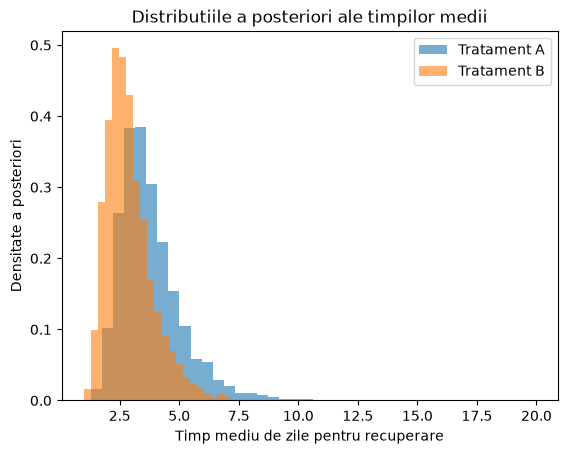

HDI 95% timp mediu A: (1.7151812617840998, 6.401725215228218)
HDI 95% timp mediu B: (1.3293087299791884, 4.9537797397933545)


In [6]:
# b)
mean_A = trace['posterior']['mean_A'].values.flatten()
mean_B = trace['posterior']['mean_B'].values.flatten()

plt.hist(mean_A, bins=40, alpha=0.6, density=True, label='Tratament A')
plt.hist(mean_B, bins=40, alpha=0.6, density=True, label='Tratament B')
plt.xlabel('Timp mediu de zile pentru recuperare')
plt.ylabel('Densitate a posteriori')
plt.title('Distributiile a posteriori ale timpilor medii')
plt.legend()
plt.savefig('ex2_timpi_medii.png')
plt.show()

hdi_A = az.hdi(trace['posterior']['mean_A'], prob=0.95)
hdi_B = az.hdi(trace['posterior']['mean_B'], prob=0.95)
print('HDI 95% timp mediu A:', (hdi_A.sel(ci_bound='lower').item(), hdi_A.sel(ci_bound='upper').item()))
print('HDI 95% timp mediu B:', (hdi_B.sel(ci_bound='lower').item(), hdi_B.sel(ci_bound='upper').item()))

In [7]:
# c)
prob_B_mai_bun = (trace['posterior']['mean_B'] < trace['posterior']['mean_A']).mean().item()
print('P(timp mediu B < timp mediu A):', prob_B_mai_bun)

P(timp mediu B < timp mediu A): 0.711


In [ ]:
# d)
with model:
    A_new = pm.Exponential('A_new', lam=lambda_A)
    B_new = pm.Exponential('B_new', lam=lambda_B)
    ppc = pm.sample_posterior_predictive(trace, var_names=['A_new', 'B_new'], random_seed=42)

A_new = ppc['posterior_predictive']['A_new']
B_new = ppc['posterior_predictive']['B_new']
prob_pacient_B_mai_rapid = (B_new < A_new).mean().item()

print('P(pacient nou cu B se recupereaza mai repede decat unul cu A):', prob_pacient_B_mai_rapid)
print('Diferența față de punctul c):', prob_pacient_B_mai_rapid - prob_B_mai_bun)

Sampling: [A_new, B_new]


Output()

P(pacient nou cu B se recuperează mai repede decât unul cu A): 0.5665
Diferența față de punctul c): -0.14449999999999996
